# 02 - v1: Quant's features on different classifiers and hardware settings

The original QUANT method with measurement and choice of classifiers added.<br>
All four classifiers are fed the same Quant features: ExtraTrees (the original QUANT classifier), XGBoost, CatBoost and TabPFN.<br>
TabPFN gets only the 500 most important of them (its feature budget), ranked by an ExtraTrees fit on the
training data.<br>
Seed 0 in every run.<br>

| Setting | QUANT transform + ExtraTrees | XGBoost, CatBoost, TabPFN | Small datasets | Medium datasets |
|---|---|---|---|---|
| **all cores + GPU** | all 22 CPU cores | GPU | `v1_smoke-small-r0_allcores-gpu.csv` | `v1_smoke-medium-r0_allcores-gpu.csv` |
| **1 core + GPU** | 1 CPU core | GPU (fed by 1 CPU core) | `v1_smoke-small-r0_onecore-gpu.csv` | `v1_smoke-medium-r0_onecore-gpu.csv` |
| **1 core, CPU only** | 1 CPU core | 1 CPU core (the paper's hardware budget) | `v1_smoke-small-r0_onecore-cpu.csv` | not run (see below) |

Small datasets: Coffee, GunPoint, ItalyPowerDemand, ECG200, Beef;<br>
Medium datasets: ChlorineConcentration, UWaveGestureLibraryX, SharePriceIncrease, PhalangesOutlinesCorrect, AconityMINIPrinterLargeEq;<br>
**one resample per run: resample 0** (the original train/test split), so 5 runs per classifier and setting. One
resample is enough here: the notebook compares hardware settings, and every setting runs the same datasets, splits and
seed, so a difference between settings comes from the hardware, not from the split.

**"1 core, CPU only" is run on the small datasets only.** On the medium datasets it was started and stopped: TabPFN
is built for the GPU, and without it the run would have taken several hours. It would also prove little: the small
datasets already show that TabPFN and CatBoost are 15-17x slower without the GPU (TabPFN about 300x slower than
ExtraTrees), and ExtraTrees on one core is already in "1 core + GPU" (ExtraTrees never uses the GPU).

**How the files are produced:** see `experiments.md`, v1 (one resample, resample 0; the one-core runs on
their own, so that their timings are not disturbed).

- **Part A** - one core vs all cores, with the GPU on the small and the medium datasets, and without it on the small
  datasets: accuracy,
  time, what the cores and the GPU add, and whether the hardware changes the results. The paper times QUANT on one CPU
  core; a GPU cannot be limited to "one core's worth", so "1 core, CPU only" is the fair same-hardware setting and
  "1 core + GPU" shows what the GPU adds.
- **Part B** - small vs medium datasets (all cores + GPU): how the classifiers compare when there are more training cases.

All results are shown as plots; times are in seconds on linear axes.

Caveat: smoke tests (5 datasets per group, one resample each), a first signal, not a conclusion.

## 1. Settings and data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import CLASSIFIERS, COLORS, LABELS, MUTED, RESULTS_DIR, TEXT, dataset_list, load_runs, short, style

style()
GROUPS = ["small", "medium"]
SETTINGS = ["all cores + GPU", "1 core + GPU", "1 core, CPU only"]
SETTINGS_OF = {"small": SETTINGS, "medium": SETTINGS[:2]}       # "1 core, CPU only" is not run on the medium datasets
SETTING_FILES = {"all cores + GPU": "allcores-gpu", "1 core + GPU": "onecore-gpu", "1 core, CPU only": "onecore-cpu"}
SETTING_COLORS = {"all cores + GPU": "#0e8a8a", "1 core + GPU": "#7cc4c4", "1 core, CPU only": "#8c8b85"}
GROUP_COLORS = {"small": "#9cc3ef", "medium": "#2a78d6"}
DATASETS = {group: dataset_list(f"smoke-{group}") for group in GROUPS}

# one table with every run of the five files, each run marked with its dataset group and hardware setting
frames = []
for group in GROUPS:
    for setting in SETTINGS_OF[group]:
        d = load_runs(RESULTS_DIR / f"v1_smoke-{group}-r0_{SETTING_FILES[setting]}.csv")
        d["group"] = group
        d["setting"] = setting
        frames.append(d)
runs = pd.concat(frames, ignore_index=True)
ok = runs[runs["status"] == "ok"]
fit_predict = ok.groupby(["group", "classifier", "setting"])["fit_predict"].mean()       # mean seconds per run

In [2]:
def grouped_bars(ax, values, groups, series, colors, fmt="{:.3f}", rotation=0, fontsize=8.5):
    """One group of bars per group, one bar per series (values[(group, series)]), each bar labelled with its value."""
    x = np.arange(len(groups))
    width = 0.8 / len(series)
    for k, s in enumerate(series):
        offset = (k - (len(series) - 1) / 2) * width              # the series side by side, centred on x
        bars = ax.bar(x + offset, [values[(g, s)] for g in groups], width, color=colors[s], edgecolor="white",
                      linewidth=1.2, label=s)
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=fontsize, color=TEXT, rotation=rotation)
    return x

# Part A - One core vs all cores, with and without the GPU (small and medium datasets)

## 2. What the cores and the GPU add

Speed-up of fit + predict: how many times faster a setting is than a baseline (1.0 = the same speed, below 1 =
slower). Left: small datasets, against the fair baseline "1 core, CPU only". Right: medium datasets, against "1 core +
GPU" (the medium datasets have no CPU-only run), so only the effect of the cores is shown there.

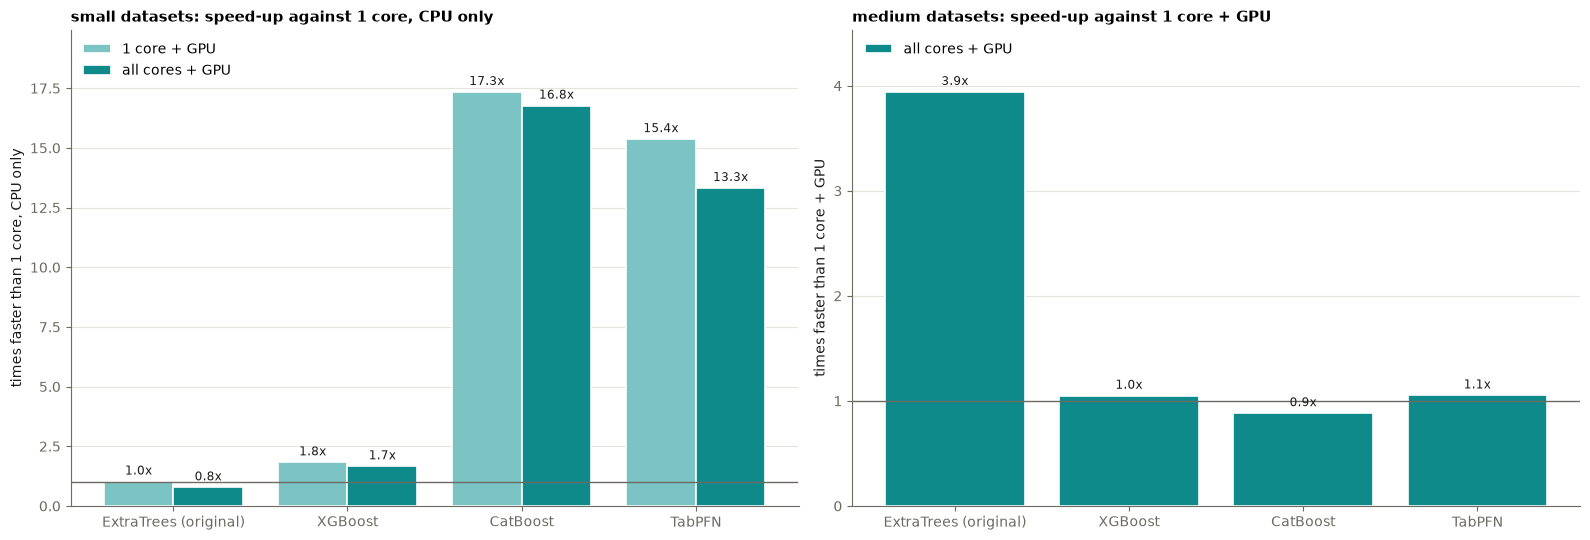

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, group in zip(axes, GROUPS):
    fp = fit_predict.loc[group].unstack()                         # rows: classifiers, columns: settings
    if group == "small":                                          # the fair baseline: one CPU core, no GPU
        base, compared = "1 core, CPU only", ["1 core + GPU", "all cores + GPU"]
    else:                                                         # no CPU-only run: only the effect of the cores
        base, compared = "1 core + GPU", ["all cores + GPU"]
    speedup = {(c, s): fp.loc[c, base] / fp.loc[c, s] for c in CLASSIFIERS for s in compared}
    x = grouped_bars(ax, speedup, CLASSIFIERS, compared, SETTING_COLORS, fmt="{:.1f}x")
    ax.axhline(1, color=MUTED, linewidth=1)
    ax.set_xticks(x, [LABELS[c] for c in CLASSIFIERS])
    ax.set_ylabel(f"times faster than {base}")
    ax.set_ylim(0, max(speedup.values()) * 1.15)
    ax.set_title(f"{group} datasets: speed-up against {base}", loc="left")
    ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

Reading the plot: the baseline (1x) is **one CPU core without the GPU**. The two bars separate the two effects:
- **the GPU** - "1 core + GPU" against the baseline (only the GPU is added). On the small datasets ExtraTrees does
  not use the GPU, so it stays at 1x; XGBoost becomes about 2x faster, CatBoost and TabPFN 15-17x.
- **the number of cores** - "all cores + GPU" against "1 core + GPU" (only the cores change). On the small datasets
  all four classifiers are *slower* with 22 cores than with one, because starting and coordinating the threads costs
  more than it saves on such tiny training sets.

Medium datasets (right, baseline "1 core + GPU"): the 22 cores pay off only for ExtraTrees (about 4x faster);
XGBoost and TabPFN gain about 5%, and CatBoost is even a little slower with 22 cores than with one.

## 3. Does the hardware change the results?

Small datasets. Each point is one run (one dataset, resample 0): x = the accuracy on all cores + GPU; y = the same
run on one core, **with the GPU** (circles: only the number of cores differs) or **without it** (diamonds: the GPU is
also left out). Points on the diagonal are identical. Same features and seed in every setting.

The medium datasets are not plotted: they have no CPU-only run, and on one core with the GPU every classifier gave
exactly the same accuracy as on all cores (20 of 20 runs).

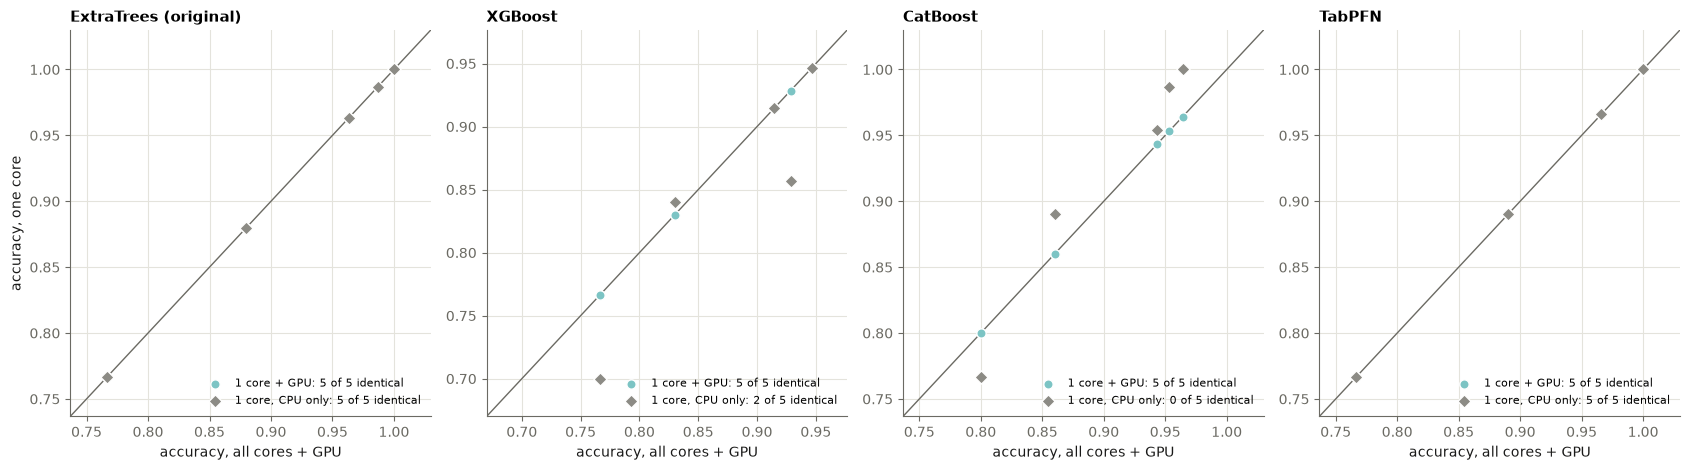

In [4]:
small = ok[ok["group"] == "small"]
paired = small.pivot_table(index=["dataset", "resample", "classifier"], columns="setting", values="accuracy")
fig, axes = plt.subplots(1, 4, figsize=(17, 4.8))
for ax, clf in zip(axes, CLASSIFIERS):
    p = paired.xs(clf, level="classifier")                        # one row per run, one column per setting
    lo, hi = p.min().min() - 0.03, min(1.0, p.max().max()) + 0.03
    ax.plot([lo, hi], [lo, hi], color=MUTED, linewidth=1, zorder=1)                 # the diagonal: identical results
    for s, marker in [("1 core + GPU", "o"), ("1 core, CPU only", "D")]:
        same = (p[s] == p["all cores + GPU"]).sum()
        ax.scatter(p["all cores + GPU"], p[s], s=45, marker=marker, color=SETTING_COLORS[s], edgecolor="white",
                   zorder=3, label=f"{s}: {same} of {len(p)} identical")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel("accuracy, all cores + GPU")
    ax.set_title(LABELS[clf], loc="left")
    ax.grid(True, axis="both")
    ax.legend(loc="lower right", frameon=False, fontsize=8)
axes[0].set_ylabel("accuracy, one core")
fig.tight_layout()
plt.show()

On the small datasets, ExtraTrees and TabPFN give the same results on every setting. XGBoost and CatBoost train
differently on the GPU and on the CPU, so their results depend on the hardware; for them the hardware must always be
stated. The number of cores alone changes no result, on the small or on the medium datasets.

## 4. Time per dataset

Fit + predict time per dataset (resample 0), one figure per dataset group, one panel per classifier,
one bar per setting. Seconds, linear axes; each panel has its own scale.

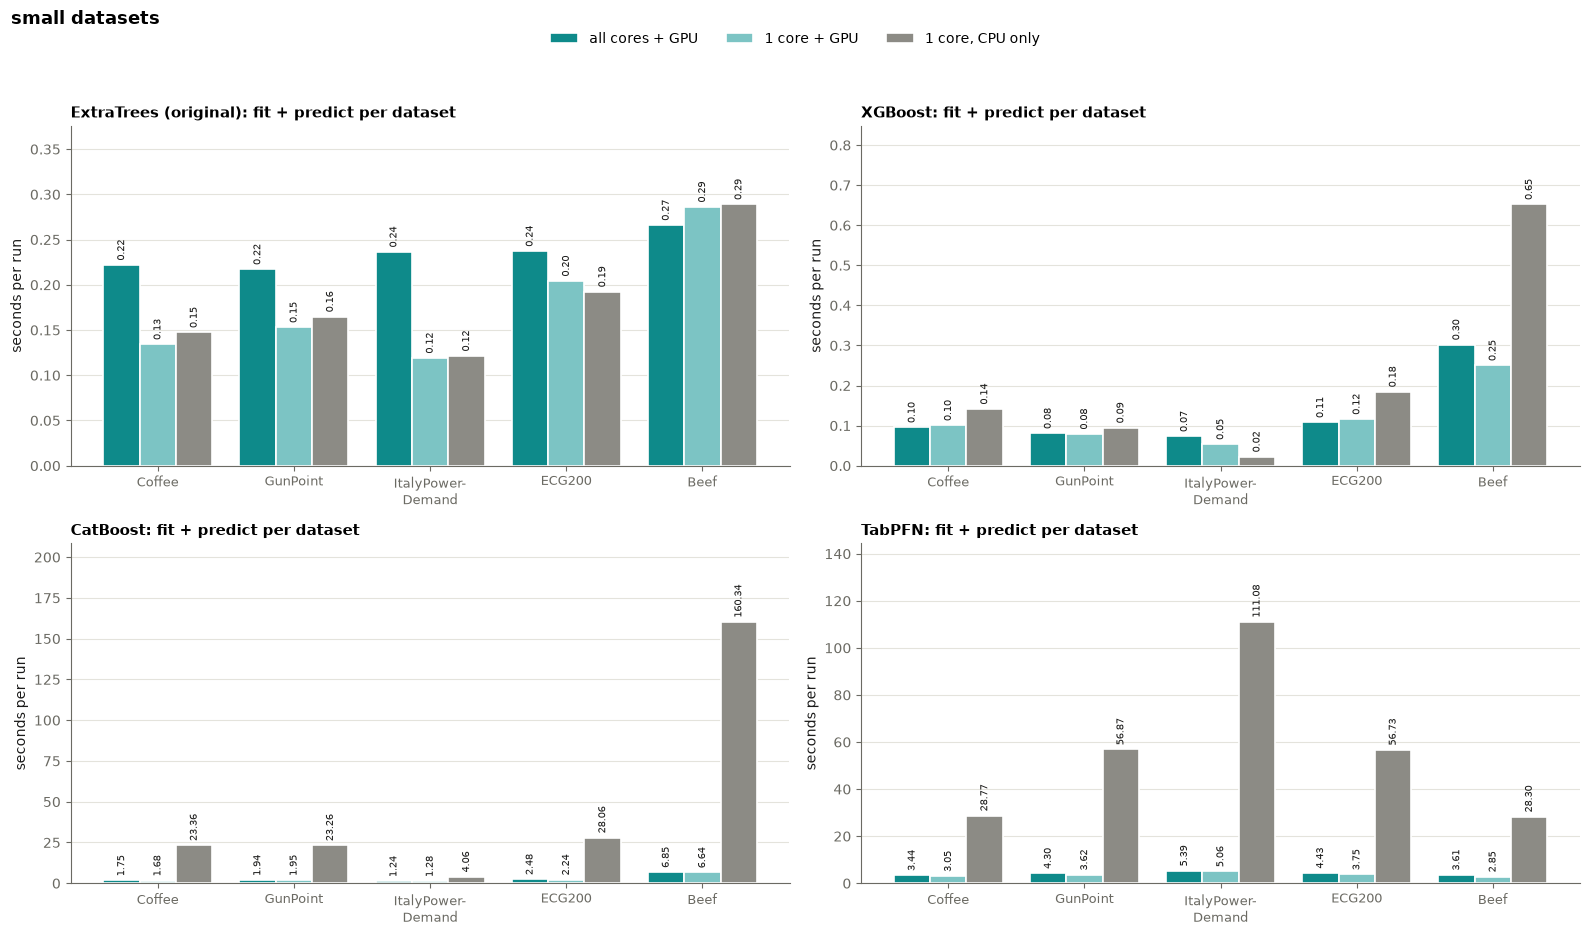

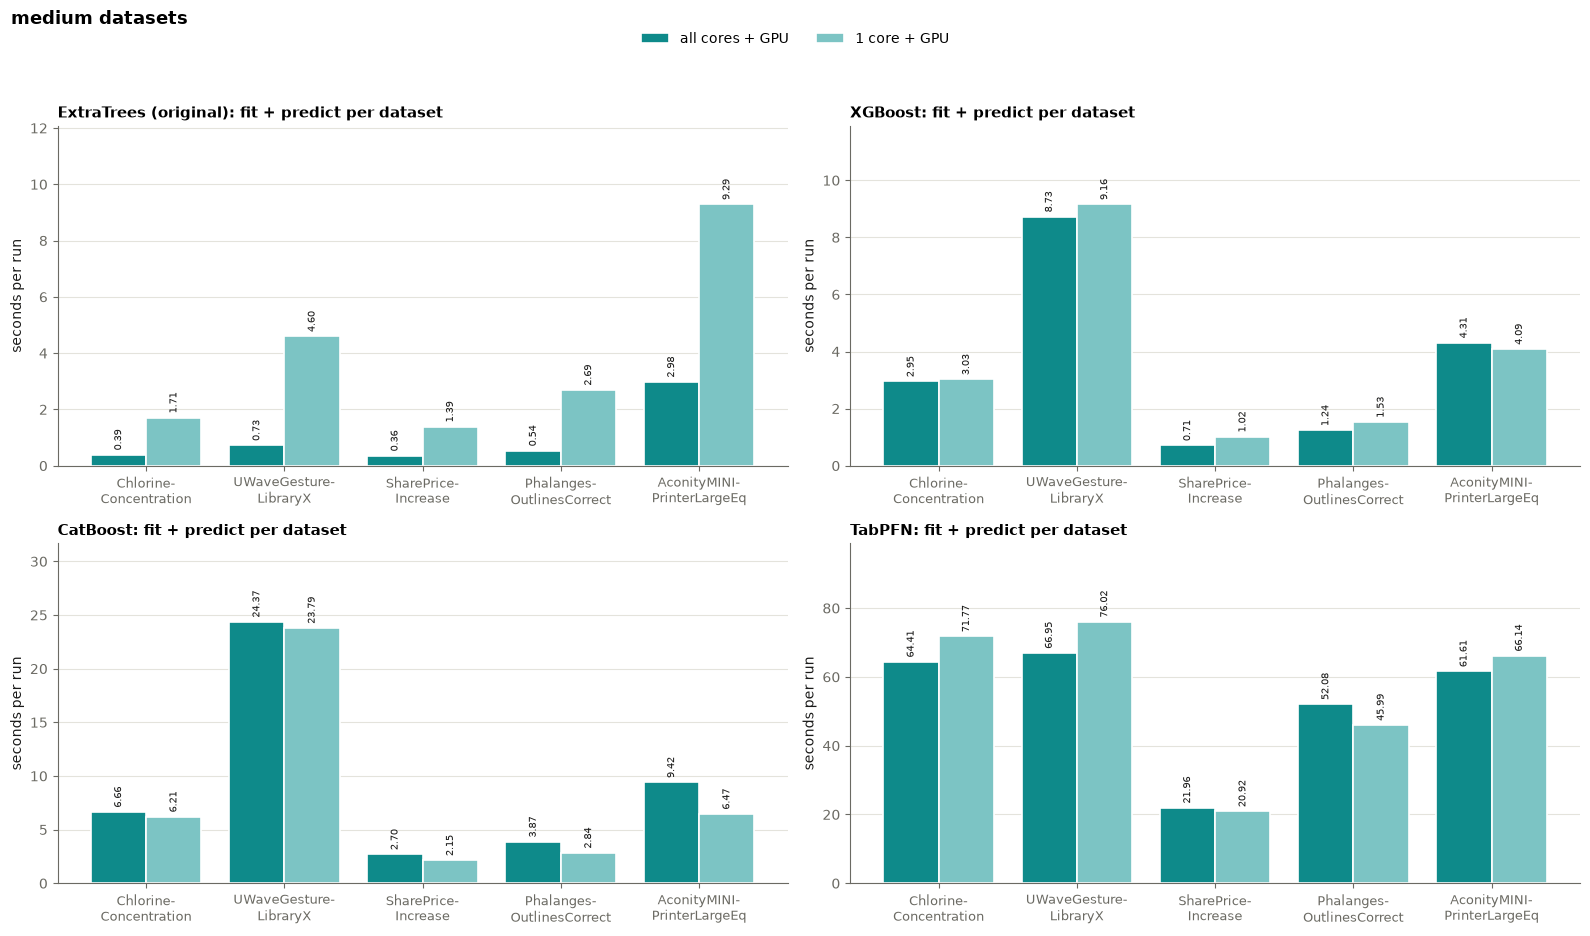

In [5]:
for group in GROUPS:
    per_dataset = ok[ok["group"] == group].groupby(["classifier", "dataset", "setting"])["fit_predict"].mean()
    names, settings = DATASETS[group], SETTINGS_OF[group]
    fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))
    for ax, clf in zip(axes.flat, CLASSIFIERS):
        values = {(d, s): per_dataset[(clf, d, s)] for d in names for s in settings}
        x = grouped_bars(ax, values, names, settings, SETTING_COLORS, fmt="{:.2f}", rotation=90, fontsize=7.5)
        ax.set_xticks(x, [short(d) for d in names], fontsize=9)
        ax.set_ylim(0, max(values.values()) * 1.3)
        ax.set_ylabel("seconds per run")
        ax.set_title(f"{LABELS[clf]}: fit + predict per dataset", loc="left")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 0.97))
    fig.suptitle(f"{group} datasets", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

# Part B - Small vs medium datasets (all cores + GPU)

## 5. Accuracy and probability quality, small vs medium

One group of bars per classifier: light = small datasets (28 to 100 training cases), dark = medium datasets
(467 to 2,403 training cases). Mean over the 5 datasets each.

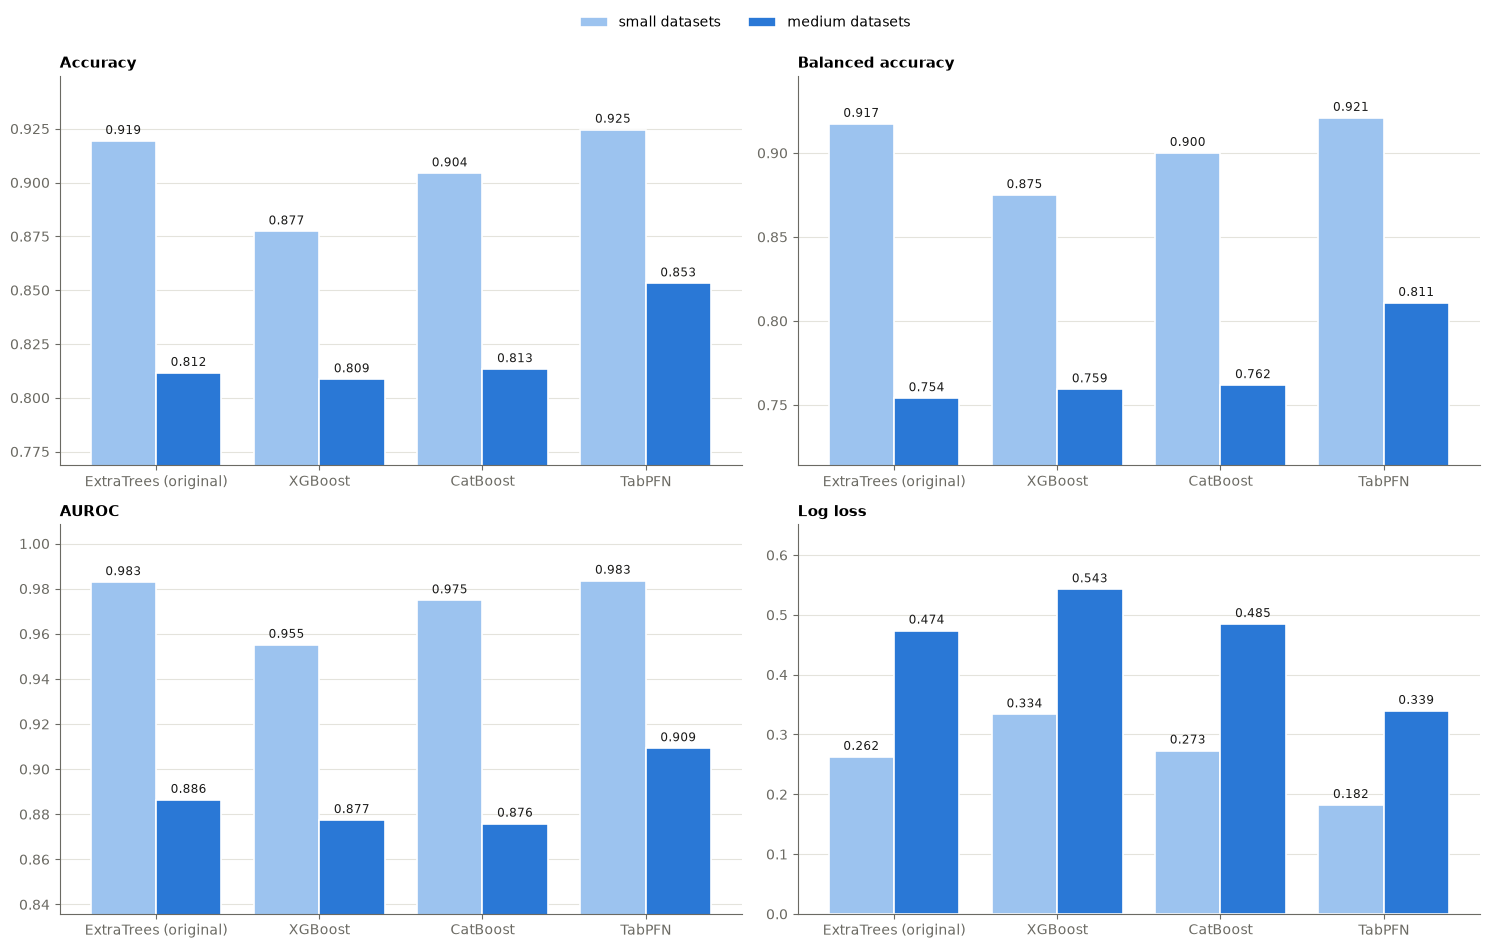

In [6]:
# the mean of each metric per classifier and dataset group, all cores + GPU (used again in sections 6 and 7)
by_group = ok[ok["setting"] == "all cores + GPU"].groupby(["classifier", "group"])[
    ["accuracy", "balanced_accuracy", "auroc", "log_loss", "fit_predict", "total_time"]].mean()

panels = [("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced accuracy"), ("auroc", "AUROC"), ("log_loss", "Log loss")]
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
for ax, (metric, title) in zip(axes.flat, panels):
    values = by_group[metric].to_dict()                           # (classifier, group) -> mean
    x = grouped_bars(ax, values, CLASSIFIERS, GROUPS, GROUP_COLORS)
    ax.set_xticks(x, [LABELS[c] for c in CLASSIFIERS])
    ax.set_title(title, loc="left")
    if metric == "log_loss":                                      # log loss from 0; the others zoomed in on the values
        ax.set_ylim(0, max(values.values()) * 1.2)
    else:
        ax.set_ylim(min(values.values()) - 0.04, min(1.0, max(values.values())) + 0.025)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, ["small datasets", "medium datasets"], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

Note: the y-axes of accuracy, balanced accuracy and AUROC do not start at 0, to make the differences visible.

## 6. Time, small vs medium

Fit + predict time per run in seconds (linear axis). TabPFN's time grows with the number of cases (it compares every
test case with the training data), ExtraTrees' much less.

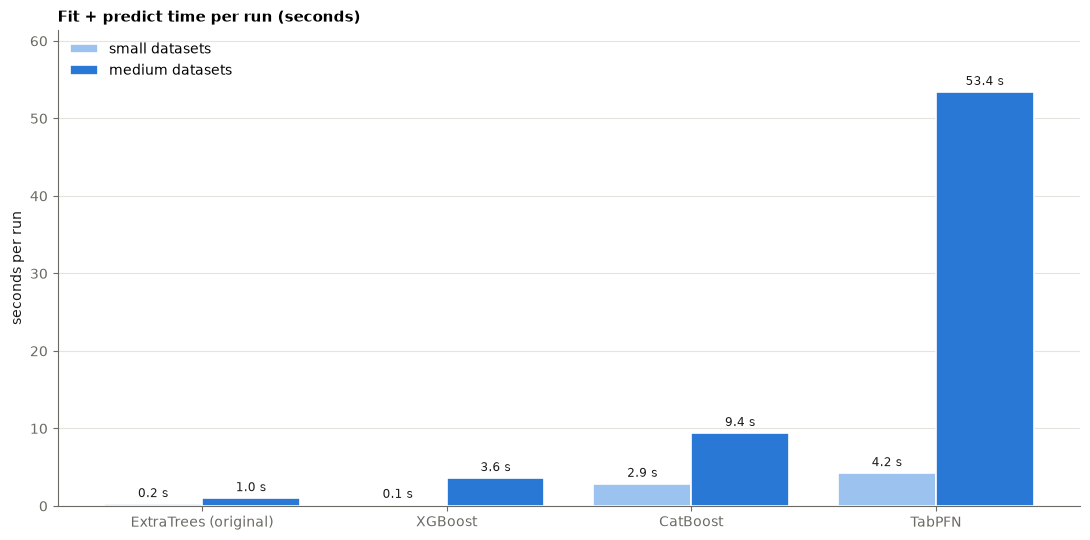

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))
values = by_group["fit_predict"].to_dict()
x = grouped_bars(ax, values, CLASSIFIERS, GROUPS, GROUP_COLORS, fmt="{:.1f} s")
ax.set_xticks(x, [LABELS[c] for c in CLASSIFIERS])
ax.set_ylim(0, max(values.values()) * 1.15)
ax.set_ylabel("seconds per run")
ax.set_title("Fit + predict time per run (seconds)", loc="left")
ax.legend(["small datasets", "medium datasets"], loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

## 7. Accuracy vs time

One point per classifier and dataset group (circles: small, squares: medium). Up and to the left is better.
Total time per run (QUANT transform + fit + predict), seconds, linear axis.

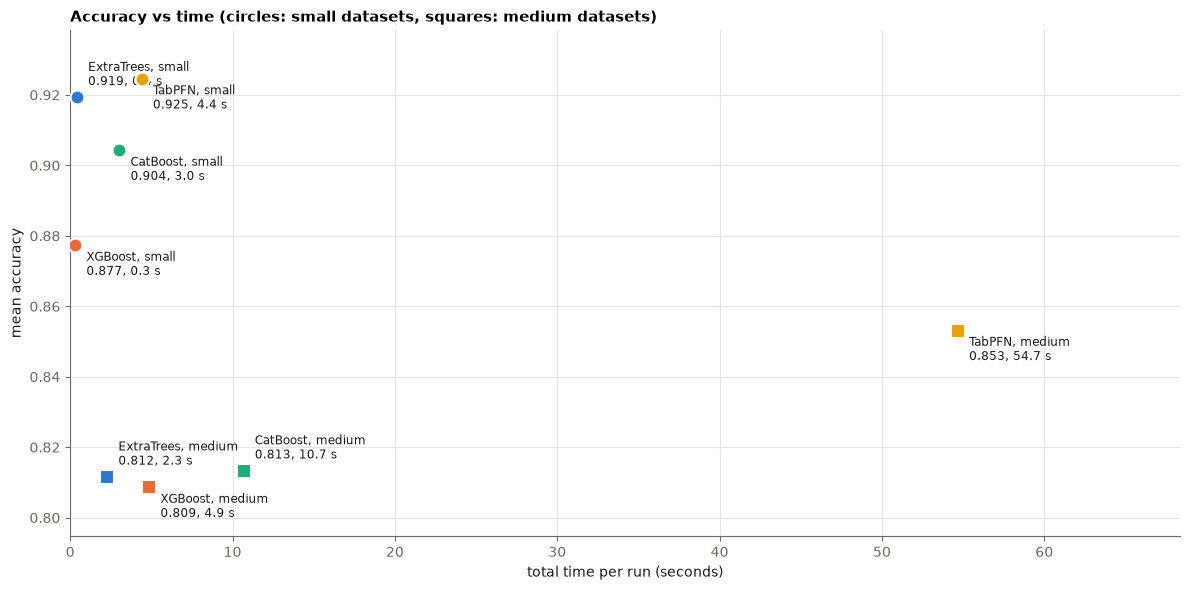

In [8]:
# where each label goes (offset in points, vertical alignment), so that the labels of nearby points do not overlap
LABEL_PLACE = {("extratrees", "small"): (8, 6, "bottom"), ("extratrees", "medium"): (8, 6, "bottom"),
               ("catboost", "medium"): (8, 6, "bottom")}
fig, ax = plt.subplots(figsize=(12, 6))
for clf in CLASSIFIERS:
    for group, marker in [("small", "o"), ("medium", "s")]:
        row = by_group.loc[(clf, group)]
        ax.scatter(row["total_time"], row["accuracy"], s=100, marker=marker, color=COLORS[clf], edgecolor="white",
                   linewidth=1.5, zorder=3)
        dx, dy, va = LABEL_PLACE.get((clf, group), (8, -3, "top"))
        name = LABELS[clf].split(" (")[0]                          # "ExtraTrees (original)" -> "ExtraTrees"
        ax.annotate(f"{name}, {group}\n{row['accuracy']:.3f}, {row['total_time']:.1f} s",
                    (row["total_time"], row["accuracy"]), xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                    color=TEXT, va=va)
ax.set_xlim(0, by_group["total_time"].max() * 1.25)
ax.set_xlabel("total time per run (seconds)")
ax.set_ylabel("mean accuracy")
ax.set_title("Accuracy vs time (circles: small datasets, squares: medium datasets)", loc="left")
ax.grid(True, axis="both")
ax.margins(y=0.12)
fig.tight_layout()
plt.show()

## 8. Observations

- **Most accurate: TabPFN on both groups** (small 0.925, medium 0.853), never worse than ExtraTrees on any dataset,
  and with the best probabilities. ExtraTrees is second on small (0.919); on medium ExtraTrees, CatBoost and XGBoost
  are tied (0.809-0.813).
- **Fastest: XGBoost on small (0.13 s), ExtraTrees on medium (1.0 s).** TabPFN is the slowest (4.2 s / 53.4 s).
- **The GPU** makes CatBoost 17x and TabPFN 15x faster on one core; without it they are about 300x slower than
  ExtraTrees. **The 22 cores** help only ExtraTrees on medium (3.9x); on small, one core is as fast or faster.
- **Same results on every setting: ExtraTrees and TabPFN.** XGBoost and CatBoost change between CPU and GPU, so
  their hardware must be stated. The number of cores alone changes nothing.
- **From small to medium,** TabPFN's lead over ExtraTrees grows from +0.006 to +0.041, and the boosters catch up
  with ExtraTrees.
